# Exploração — preços de combustíveis (ANP, 2023–2025)

Análise exploratória que sustenta o dashboard. Lê os agregados mensais versionados em `data/app/` (gerados por `src/load.py` → `src/export.py`) e usa as mesmas funções de `src/metrics.py`, então os números aqui batem com o app e com as queries de `sql/analysis/`.

Foco em **diesel**, o combustível que mais pesa no custo de uma operação de distribuição.

## 1. Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
import metrics  # noqa: E402

sns.set_theme(style="whitegrid", context="notebook")
CORES_REGIAO = {"Sudeste": "#2a78d6", "Nordeste": "#eb6834", "Sul": "#1baf7a", "Centro-Oeste": "#eda100", "Norte": "#e87ba4"}
CORES_CATEGORIA = {"GASOLINA": "#2a78d6", "ETANOL": "#eb6834", "DIESEL": "#1baf7a"}

## 2. Dados

In [2]:
painel = pd.read_parquet(RAIZ / "data/app/precos_uf_mensal.parquet")
produtos = pd.read_parquet(RAIZ / "data/app/precos_produto_mensal.parquet")
bandeiras = pd.read_parquet(RAIZ / "data/app/precos_bandeira_mensal.parquet")
meta = pd.read_json(RAIZ / "data/app/meta.json", typ="series")
print(meta.to_string())
diesel = painel[painel["categoria"] == "DIESEL"]
painel.head()

ultima_carga      2026-10-31T13:12:01+00:00
periodo_inicio                   2023-01-02
periodo_fim                      2025-12-31
registros                           2607114
ufs                                      27
municipios                              461


,data,ano,mes,uf,categoria,preco_medio,preco_min,preco_max,desvio_postos,n_amostras,nome_estado,regiao
0,2023-01-01,2023,1,AC,DIESEL,7.2491,6.95,7.75,0.1704,53,Acre,Norte
1,2023-01-01,2023,1,AC,ETANOL,4.3673,4.15,4.59,0.1177,22,Acre,Norte
2,2023-01-01,2023,1,AC,GASOLINA,5.3169,5.08,5.58,0.0964,62,Acre,Norte
3,2023-01-01,2023,1,AL,DIESEL,6.7177,5.93,7.67,0.4232,184,Alagoas,Nordeste
4,2023-01-01,2023,1,AL,ETANOL,4.1195,3.59,5.78,0.3574,191,Alagoas,Nordeste


## 3. Qualidade dos dados

In [3]:
print("Linhas (UF x mês x combustível):", len(painel))
print("Meses:", painel["data"].nunique(), "| UFs:", painel["uf"].nunique())
print("Nulos:", int(painel.isna().sum().sum()))
cobertura = painel.pivot_table(index="uf", columns="categoria", values="data", aggfunc="nunique", observed=True)
print("Pares UF/combustível com menos de 36 meses:", int((cobertura < 36).sum().sum()))
painel.groupby("categoria", observed=True)["n_amostras"].describe().round(0)

Linhas (UF x mês x combustível): 2916
Meses: 36 | UFs: 27
Nulos: 0
Pares UF/combustível com menos de 36 meses: 0


,count,mean,std,min,25%,50%,75%,max
categoria,,,,,,,,
DIESEL,972.0,796.0,1078.0,13.0,235.0,378.0,891.0,6431.0
ETANOL,972.0,589.0,1004.0,1.0,149.0,230.0,592.0,5982.0
GASOLINA,972.0,1239.0,1808.0,52.0,371.0,516.0,1350.0,10959.0


## 4. Pergunta 1 — variação por região e estado

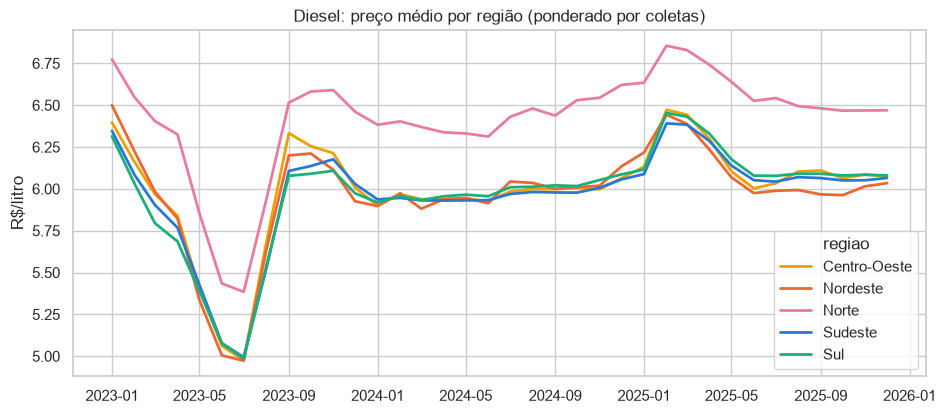

,regiao,n_amostras,preco_medio
3,Sudeste,344149,5.953
1,Nordeste,152623,5.956
4,Sul,147231,5.958
0,Centro-Oeste,63751,5.979
2,Norte,66194,6.400


In [4]:
reg = metrics.media_ponderada(diesel, ["data", "regiao"])
fig, ax = plt.subplots(figsize=(11, 4.5))
sns.lineplot(data=reg, x="data", y="preco_medio", hue="regiao", palette=CORES_REGIAO, ax=ax, linewidth=2)
ax.set(title="Diesel: preço médio por região (ponderado por coletas)", xlabel="", ylabel="R$/litro")
plt.show()
metrics.media_ponderada(diesel, ["regiao"]).sort_values("preco_medio").round(3)

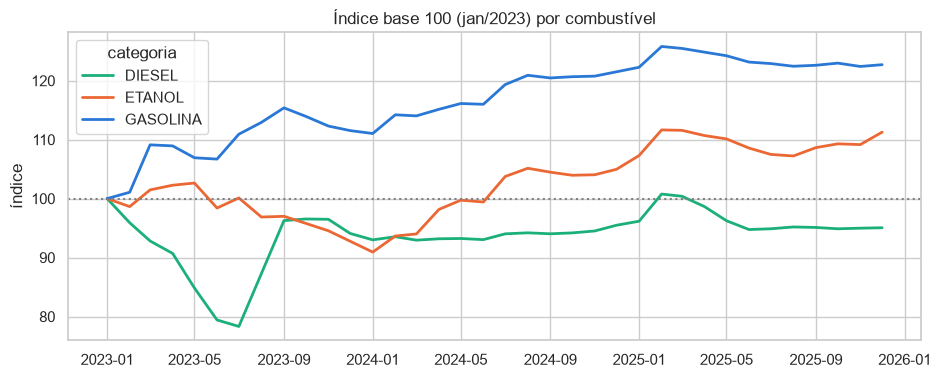

In [5]:
idx = metrics.indice_base_100(painel, "categoria")
fig, ax = plt.subplots(figsize=(11, 4))
sns.lineplot(data=idx, x="data", y="indice", hue="categoria", palette=CORES_CATEGORIA, ax=ax, linewidth=2)
ax.axhline(100, color="gray", ls=":")
ax.set(title="Índice base 100 (jan/2023) por combustível", xlabel="", ylabel="índice")
plt.show()

## 5. Pergunta 2 — sazonalidade

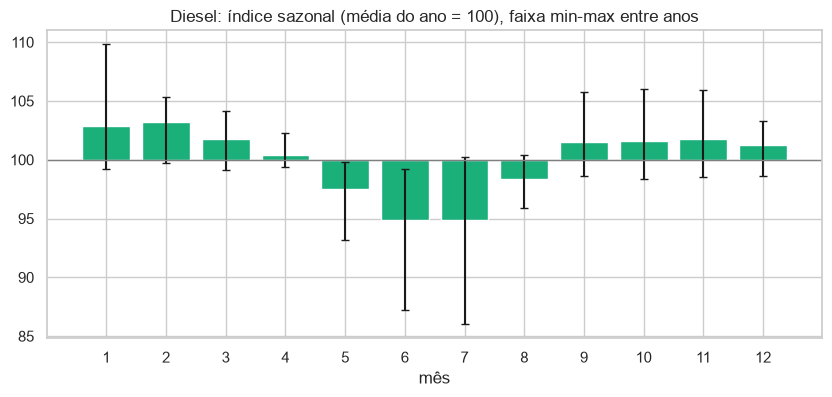

,mes,indice_medio,indice_min,indice_max,n_anos
0,1,102.9,99.2,109.8,3
1,2,103.2,99.7,105.3,3
2,3,101.7,99.1,104.1,3
3,4,100.4,99.4,102.3,3
4,5,97.5,93.2,99.8,3
5,6,94.9,87.2,99.2,3
6,7,94.9,86.0,100.3,3
7,8,98.3,95.9,100.4,3
8,9,101.5,98.6,105.7,3
9,10,101.6,98.4,106.0,3


In [6]:
saz = metrics.indice_sazonal(diesel)
fig, ax = plt.subplots(figsize=(10, 4))
erro = [saz["indice_medio"] - saz["indice_min"], saz["indice_max"] - saz["indice_medio"]]
ax.bar(saz["mes"], saz["indice_medio"] - 100, bottom=100, color="#1baf7a", yerr=erro, capsize=3)
ax.axhline(100, color="gray", lw=1)
ax.set(title="Diesel: índice sazonal (média do ano = 100), faixa min-max entre anos", xlabel="mês", xticks=range(1, 13))
plt.show()
saz.round(1)

Com apenas 3 anos, o vale de junho/julho é fortemente influenciado pela queda pontual do diesel em 2023 (note o traço longo). O padrão de **fevereiro mais caro** é mais consistente que o de julho mais barato.

## 6. Pergunta 3 — volatilidade e dispersão

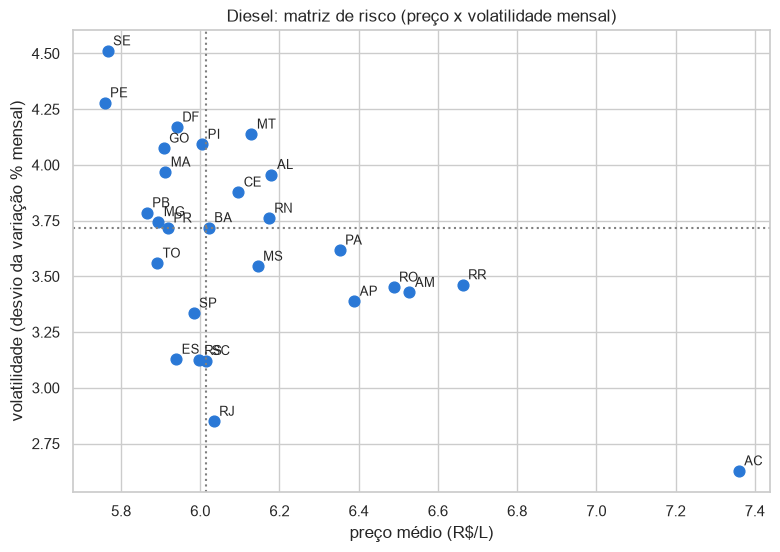

,uf,preco_medio,volatilidade,n_meses,dispersao
0,SE,5.77,4.51,36,4.52
1,PE,5.76,4.28,36,4.45
2,DF,5.94,4.17,36,3.32
3,MT,6.13,4.14,36,5.34
4,PI,6.00,4.09,36,4.18


In [7]:
vol = metrics.volatilidade_temporal(diesel)
disp = metrics.dispersao_postos(diesel)
risco = vol.merge(disp[["uf", "dispersao"]], on="uf")
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(risco["preco_medio"], risco["volatilidade"], s=60, color="#2a78d6")
for _, r in risco.iterrows():
    ax.annotate(r["uf"], (r["preco_medio"], r["volatilidade"]), xytext=(4, 4), textcoords="offset points", fontsize=9)
ax.axvline(risco["preco_medio"].median(), color="gray", ls=":")
ax.axhline(risco["volatilidade"].median(), color="gray", ls=":")
ax.set(title="Diesel: matriz de risco (preço x volatilidade mensal)", xlabel="preço médio (R$/L)",
       ylabel="volatilidade (desvio da variação % mensal)")
plt.show()
risco.sort_values("volatilidade", ascending=False).head(5).round(2)

## 7. Pergunta 4 — gap regional

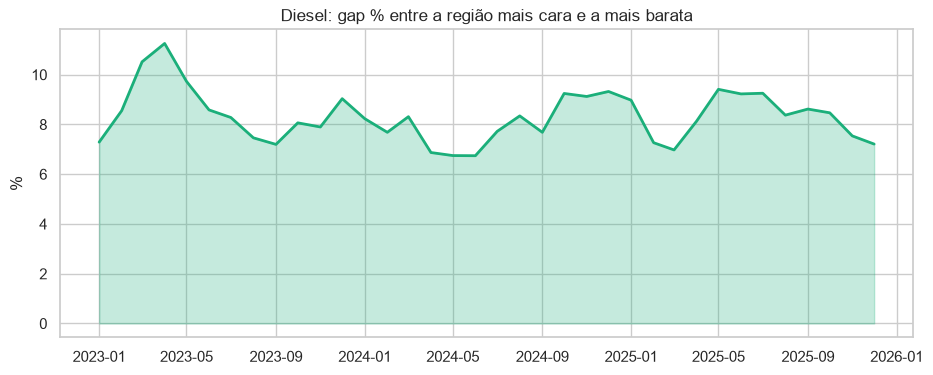

ano
2023    8.65
2024    8.00
2025    8.29
Name: gap_pct, dtype: float64

In [8]:
gap = metrics.gap_regional(diesel)
fig, ax = plt.subplots(figsize=(11, 4))
ax.fill_between(gap["data"], gap["gap_pct"], color="#1baf7a", alpha=0.25)
ax.plot(gap["data"], gap["gap_pct"], color="#1baf7a", lw=2)
ax.set(title="Diesel: gap % entre a região mais cara e a mais barata", xlabel="", ylabel="%")
plt.show()
gap.assign(ano=gap["data"].dt.year).groupby("ano")["gap_pct"].mean().round(2)

## 8. Extra — etanol vs gasolina e bandeiras

In [9]:
recente = painel[painel["data"] > painel["data"].max() - pd.DateOffset(months=3)]
par = metrics.paridade_etanol_gasolina(recente, ["uf"]).sort_values("razao")
print("Etanol compensa em:", par.loc[par["etanol_compensa"], "uf"].tolist())
premio_s10 = metrics.premio_produto(produtos, "DIESEL S10", "DIESEL")["premio_pct"].mean()
print(f"Prêmio médio do S10 sobre o diesel comum: {premio_s10:.2f}%")
b = metrics.media_ponderada(bandeiras[bandeiras["categoria"] == "DIESEL"], ["bandeira"])
branca = b.loc[b["bandeira"] == "BRANCA", "preco_medio"].iloc[0]
b["premio_vs_branca_pct"] = (b["preco_medio"] / branca - 1) * 100
b.sort_values("premio_vs_branca_pct").round(3)

Etanol compensa em: ['MS', 'SP', 'MT', 'PR']
Prêmio médio do S10 sobre o diesel comum: 1.18%


,bandeira,n_amostras,preco_medio,premio_vs_branca_pct
1,BRANCA,283072,5.891,0.000
0,ALESAT,28024,5.964,1.232
4,RAIZEN,99898,5.990,1.686
2,IPIRANGA,167729,6.066,2.969
3,OUTRAS,49793,6.090,3.372
5,VIBRA,145432,6.092,3.416


## 9. Conclusões

1. **O problema é o Norte, não um gradiente nacional.** Sudeste, Nordeste e Sul pagam praticamente o mesmo pelo diesel (≈R$ 5,95–5,96/L no período); o Norte paga **7,5% a mais** (R$ 6,40). O Acre chega a **+24%** sobre a média nacional.
2. **Diesel caiu, gasolina subiu.** De jan/2023 a dez/2025 o diesel recuou **4,9%** (26 de 27 estados mais baratos), enquanto a gasolina subiu **22,7%** e o etanol **11,3%**.
3. **Sazonalidade existe, mas é indicativa.** Fevereiro tem o maior índice médio (≈3% acima da média do ano) e jun/jul o menor (≈5% abaixo), mas o vale é puxado pela queda de 2023 — com 3 anos de dados, vale tratar como tendência, não regra.
4. **Caro ≠ instável.** O Acre é o mais caro e o *mais estável* (±2,6%/mês); Sergipe, Pernambuco e DF são os mais voláteis (±4,2–4,5%/mês). Já a dispersão entre postos é maior no Amazonas (8,3%) e no Pará (7,8%).
5. **Gap regional estável:** 8,7% (2023) → 8,0% (2024) → 8,3% (2025).
6. **Etanol compensa em só 4 estados** (MS, MT, PR, SP) no fim de 2025; bandeiras grandes cobram até **+3,4%** sobre postos de bandeira branca no diesel.